# Modèle de Cramér-Lundberg avec un processus de comptage « à impact »

On étudie ce que deviennent les propriétés du modèle de Cramér-Lundberg

$$R_t = u + ct - \sum_{i=1}^{N_t} Y_i$$

quand le processus de Poisson $N$ est remplacé par un modèle à impact : chaque sinistre « spontané » peut en déclencher d'autres peu de temps après (catastrophes naturelles, cyber, soins dentaires en série...).

Plan :
1. Rappels sur le modèle de Poisson (référence)
2. Le modèle à impact : construction et simulation
3. Espérance et variance du nombre de sinistres à toute date
4. Rôle des paramètres
5. Montants des sinistres : lois discrètes et continues
6. Probabilité de ruine
7. Propriétés du cours : ce qui reste vrai, ce qui ne l'est plus
8. Synthèse

**Ce qui est demandé** (énoncé et consignes de l'encadrant) : comprendre le modèle, l'espérance du nombre de sinistres à toute date avec un noyau exponentiel, la simulation par thinning, l'analyse numérique de la prime et de la probabilité de ruine, le rôle des paramètres, ce que le modèle apporte par rapport à Poisson, des montants discrets et continus.

**Ce que nous avons ajouté pour vérifier nos résultats** (non demandé dans l'énoncé, signalé par *Complément* dans la suite) : la variance exacte de $N_T$, la comparaison avec un processus de Hawkes, la comparaison avec un Poisson de même nombre moyen de sinistres, la prime par le principe de la variance, la sensibilité au facteur 2 et l'horizon long.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2024)

# paramètres du modèle
T = 10.0      # horizon en années
mu = 1.0      # fréquence des sinistres spontanés (par an)
alpha = 0.8   # force de l'impact juste après un sinistre
beta = 1.2    # vitesse à laquelle l'impact s'éteint
facteur = 2   # poids du 2e chaos : 2 dans le sujet, 1 dans l'article

## 1. Rappels : le modèle de Poisson

Avec $N$ Poisson d'intensité $\mu$ et des $Y_i$ i.i.d. indépendants de $N$, de moyenne $m$ :

- $\mathbb E[N_t]=\operatorname{Var}(N_t)=\mu t$, accroissements indépendants et stationnaires, sauts de taille 1 ;
- Wald : $\mathbb E[S_t]=\mu t\, m$ et $\operatorname{Var}(S_t)=\mu t\,\mathbb E[Y^2]$ ;
- condition de profit net : $c>\mu m$, on écrit $c=(1+\eta)\mu m$ ;
- Lundberg : $\psi(u)\le e^{-Ru}$ avec $\mu(M_Y(R)-1)=cR$ ;
- sinistres exponentiels : $\psi(u)=\frac{1}{1+\eta}\exp\!\big(-\frac{\eta u}{(1+\eta)m}\big)$ et $R=\frac1m-\frac{\mu}{c}$.

## 2. Le modèle à impact

On tire une mesure de Poisson d'intensité 1 sur $[0,T]\times[0,M]$ (algorithme 1 du sujet), puis :

- **sinistres spontanés** : les points sous la hauteur $\mu$, $N^{(1)}_t=\sum_i \mathbf 1_{\theta_i\le\mu}\mathbf 1_{t_i\le t}$. Le nombre de points dans $[0,t]\times[0,\mu]$ est Poisson d'aire $\mu t$, donc $N^{(1)}$ est un Poisson($\mu$) ;
- **sinistres induits** : chaque sinistre spontané en $t_{i_1}$ ouvre une zone d'impact $\{\mu<\theta\le\mu+\Phi(t-t_{i_1})\}$ avec le noyau exponentiel $\Phi(u)=\alpha e^{-\beta u}$. Un point qui tombe dedans est un sinistre induit :

$$N^{(2)}_t = 2\sum_{i_1}\sum_{i_2:\,t_{i_2}>t_{i_1}}\mathbf 1_{\theta_{i_1}\le\mu}\,\mathbf 1_{\mu<\theta_{i_2}\le\mu+\Phi(t_{i_2}-t_{i_1})}\,\mathbf 1_{t_{i_2}\le t}.$$

Contraintes : $\mu>0$, $0<\alpha<\beta$ et $M\ge\mu+\alpha$ pour que la zone d'impact tienne dans le rectangle (on prend $M=\mu+\alpha$). C'est l'idée du thinning (Chen) : on garde un point quand sa hauteur est sous l'intensité.

Les zones d'impact sont au-dessus de $\mu$ : les points « parents » et les points « enfants candidats » sont donc dans des régions disjointes, et donc indépendants. Attention, $N^{(2)}$ dépend quand même de $N^{(1)}$, puisque les zones sont placées là où sont les parents.

**Comparaison avec l'article.** Dans Hillairet & Réveillac (2024, Déf. 5.1 et Prop. 5.2), la 2e génération s'écrit $\frac1{2!}I^2(b_2)$ avec $b_2$ qui utilise $\theta_2\le\Phi(t_2-t_1)$, **sans** décalage de $\mu$ : la zone des enfants chevauche $[0,\mu]$ et un même point peut être à la fois spontané et induit, c'est le mécanisme de la Remarque 5.4. Le $\frac1{2!}$ compense la symétrisation sur les paires ordonnées, ce qui correspond à `facteur = 1`. Le sujet décale la bande au-dessus de $\mu$ et met un facteur 2 : on garde ce choix dans `facteur`.

In [2]:
def Phi(u, alpha, beta):
    # noyau exponentiel, nul avant le sinistre
    return np.where(u > 0, alpha * np.exp(-beta * np.abs(u)), 0.0)

def simule_P(T, M):
    # algorithme 1 : n ~ Poisson(MT), temps uniformes triés, hauteurs uniformes
    n = rng.poisson(M * T)
    t = np.sort(rng.uniform(0, T, n))
    theta = rng.uniform(0, M, n)
    return t, theta

def sauts_N(t, theta, mu, alpha, beta, facteur=facteur):
    # les parents sont les points sous la ligne mu
    parent = theta <= mu
    # dt[i, j] = temps écoulé entre le point i et le point j
    dt = t[None, :] - t[:, None]
    # le point j est dans la zone d'impact du point i
    dans_zone = (dt > 0) & (theta[None, :] > mu) & (theta[None, :] <= mu + Phi(dt, alpha, beta))
    # pour chaque point, combien de parents l'ont induit
    nb_parents = (dans_zone & parent[:, None]).sum(axis=0)
    return parent.astype(int), facteur * nb_parents

def simule_impact(T, mu, alpha, beta, facteur=facteur):
    # instants où N saute, et taille de chaque saut
    t, theta = simule_P(T, mu + alpha)
    s1, s2 = sauts_N(t, theta, mu, alpha, beta, facteur)
    s = s1 + s2
    return t[s > 0], s[s > 0]

def simule_poisson(T, lam):
    n = rng.poisson(lam * T)
    return np.sort(rng.uniform(0, T, n)), np.ones(n, dtype=int)

def N_sur_grille(temps, sauts, grille):
    # valeur de N_t pour chaque t de la grille
    return np.array([sauts[temps <= x].sum() for x in grille])

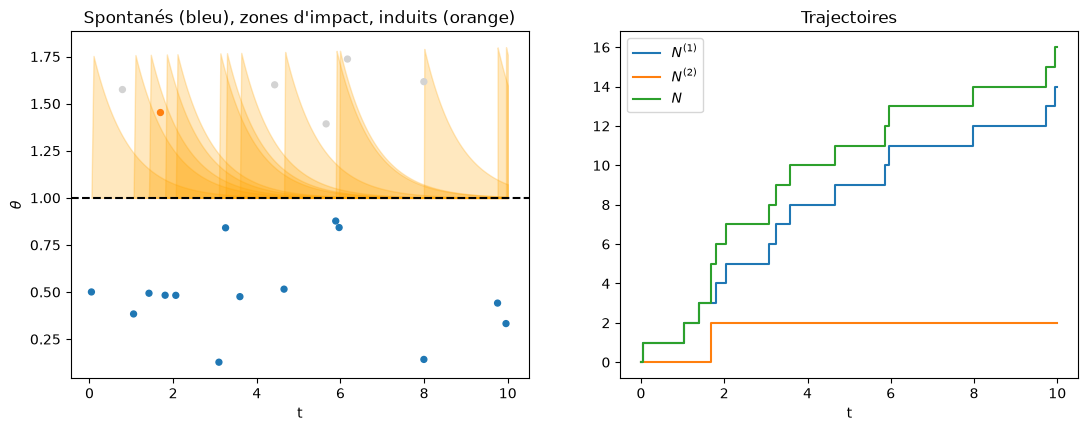

In [3]:
t, theta = simule_P(T, mu + alpha)
s1, s2 = sauts_N(t, theta, mu, alpha, beta)
grille = np.linspace(0, T, 500)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# une zone d'impact orange par sinistre spontané
for i in np.where(theta <= mu)[0]:
    x = np.linspace(t[i], T, 200)
    ax[0].fill_between(x, mu, mu + Phi(x - t[i], alpha, beta), color="orange", alpha=0.25)
couleur = np.where(theta <= mu, "tab:blue", np.where(s2 > 0, "tab:orange", "lightgrey"))
ax[0].scatter(t, theta, c=couleur, s=18)
ax[0].axhline(mu, ls="--", c="k")
ax[0].set(xlabel="t", ylabel=r"$\theta$", title="Spontanés (bleu), zones d'impact, induits (orange)")
ax[1].step(grille, N_sur_grille(t, s1, grille), label=r"$N^{(1)}$")
ax[1].step(grille, N_sur_grille(t, s2, grille), label=r"$N^{(2)}$")
ax[1].step(grille, N_sur_grille(t, s1 + s2, grille), label=r"$N$")
ax[1].legend()
ax[1].set(xlabel="t", title="Trajectoires")
plt.show()

Un point peut tomber dans les zones d'impact de plusieurs sinistres spontanés : il est compté une fois par parent et $N$ fait un saut de taille $>1$. Avec `facteur = 2`, chaque sinistre induit compte déjà pour 2. $N$ est entier, croissant et constant par morceaux, mais ce n'est pas un processus de comptage au sens strict. Dans la suite, un saut de taille $k$ correspond à $k$ sinistres survenus au même instant.

## 3. Espérance et variance du nombre de sinistres à toute date

**Espérance.** $\mathbb E[N^{(1)}_t]=\mu t$. Pour $N^{(2)}$, la formule de Mecke remplace la somme sur les paires de points par une intégrale double. Le sujet écrit l'intégrale en $t_2$ sur $[0,t_1]$ ; c'est une coquille, le noyau est nul pour $t_2<t_1$, il faut intégrer $t_1$ sur $[0,t_2]$ :

$$\mathbb E[N^{(2)}_t]=2\int_0^t\!\!\int_0^{t_2}\!\!\int_0^M\!\!\int_0^M \mathbf 1_{\theta_1\le\mu}\mathbf 1_{\mu<\theta_2\le\mu+\Phi(t_2-t_1)}\,d\theta_2\,d\theta_1\,dt_1\,dt_2
=2\mu\int_0^t\!\!\int_0^{t_2}\alpha e^{-\beta(t_2-t_1)}dt_1\,dt_2
=2\,\frac{\mu\alpha}{\beta}\Big(t-\frac{1-e^{-\beta t}}{\beta}\Big).$$

Donc
$$\boxed{\mathbb E[N_t]=\mu t+2\,\frac{\mu\alpha}{\beta}\Big(t-\frac{1-e^{-\beta t}}{\beta}\Big)}\qquad\text{et}\qquad \frac{\mathbb E[N_t]}{t}\xrightarrow[t\to\infty]{}\mu\Big(1+\frac{2\alpha}{\beta}\Big).$$

**Variance** (*Complément*, non demandé : sert à vérifier la surdispersion observée). Sachant les parents $t_1,\dots,t_p$, les enfants sont les points d'une mesure de Poisson tombés dans les zones. Si $A(s)=\frac\alpha\beta(1-e^{-\beta(T-s)})$ est l'aire de la zone d'un parent né en $s$ et $B(s,s')=\frac\alpha\beta\big(e^{-\beta(s'-s)}-e^{-\beta(T-s)}\big)$ l'aire commune aux zones de deux parents $s<s'$, la formule de la variance totale et la formule de Campbell donnent
$$\operatorname{Var}(N_T)=\mu\int_0^T\big(1+2A(s)\big)^2ds+4\Big(\mu\int_0^TA(s)\,ds+2\mu^2\iint_{s<s'}B(s,s')\,ds\,ds'\Big).$$
L'intégrale de recouvrement se ramène à une intégrale simple : $\iint_{s<s'}B(s,s')\,ds\,ds'=\alpha\int_0^T(T-v)\,v\,e^{-\beta v}\,dv$, qu'on calcule numériquement.

**Hawkes** (*Complément*, non demandé : sert de point de comparaison). Le processus de Hawkes à noyau exponentiel ($\lambda_t=\mu+\sum_{t_i<t}\alpha e^{-\beta(t-t_i)}$, stable si $\alpha<\beta$) vérifie $m'=-(\beta-\alpha)m+\beta\mu$ pour $m(t)=\mathbb E[\lambda_t]$, d'où
$$\mathbb E[H_t]=\frac{\mu\beta}{\beta-\alpha}t-\frac{\mu\alpha}{(\beta-\alpha)^2}\big(1-e^{-(\beta-\alpha)t}\big).$$
Au premier ordre en $\alpha$, $\mathbb E[H_t]\approx\mu t+\frac{\mu\alpha}{\beta}(t-\frac{1-e^{-\beta t}}{\beta})$. Avec un poids 1, l'espérance du modèle à impact coïncide avec celle des deux premières générations d'un Hawkes (le facteur 2 du sujet double le second terme). Les processus diffèrent toutefois en loi, notamment par leurs arrivées simultanées et les points partagés entre plusieurs parents.

In [4]:
def esperance_impact(t, mu, alpha, beta, facteur=facteur):
    return mu * t + facteur * mu * alpha / beta * (t - (1 - np.exp(-beta * t)) / beta)

def variance_impact(T, mu, alpha, beta, facteur=facteur):
    s = np.linspace(0, T, 2001)
    # aire de la zone d'impact d'un parent né en s (coupée à T)
    A = alpha / beta * (1 - np.exp(-beta * (T - s)))
    # aire totale des recouvrements entre zones de deux parents
    recouvrement = alpha * np.trapezoid((T - s) * s * np.exp(-beta * s), s)
    v_parents = mu * np.trapezoid((1 + facteur * A) ** 2, s)
    v_enfants = facteur ** 2 * (mu * np.trapezoid(A, s) + 2 * mu ** 2 * recouvrement)
    return v_parents + v_enfants

def esperance_hawkes(t, mu, alpha, beta):
    return mu * beta / (beta - alpha) * t - mu * alpha / (beta - alpha) ** 2 * (1 - np.exp(-(beta - alpha) * t))

def simule_hawkes(T, mu, alpha, beta):
    # thinning d'Ogata : entre deux sauts l'intensité décroît,
    # donc sa valeur actuelle majore l'intensité jusqu'au prochain saut
    s, sauts, exc = 0.0, [], 0.0   # exc : partie "excitée" de l'intensité
    while True:
        borne = mu + exc
        w = rng.exponential(1 / borne)
        s += w
        if s > T:
            return np.array(sauts), np.ones(len(sauts), dtype=int)
        exc *= np.exp(-beta * w)               # l'excitation s'éteint pendant w
        if rng.uniform() * borne <= mu + exc:  # on accepte avec proba lambda / borne
            sauts.append(s)
            exc += alpha                       # chaque sinistre fait monter l'intensité de alpha

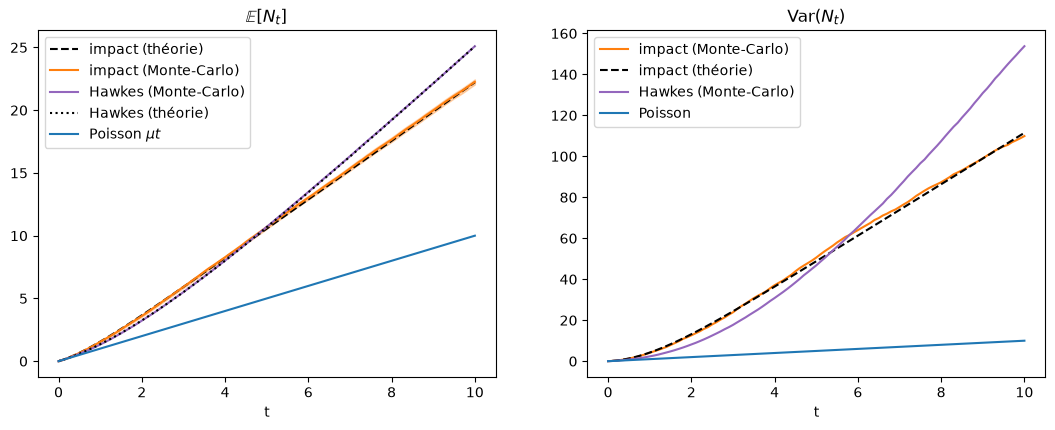

théorie dans la bande à 95 % : 95% des dates
E[N_T]   MC = 22.25 ± 0.21   théorie = 22.22
Var(N_T) MC = 109.9   théorie = 111.5   Poisson : 10.0
E[H_T]   MC = 25.10   théorie = 25.09   Var(H_T) MC = 153.8


In [5]:
K = 10000
grille = np.linspace(0, T, 101)
Ni = np.array([N_sur_grille(*simule_impact(T, mu, alpha, beta), grille) for _ in range(K)])
Nh = np.array([N_sur_grille(*simule_hawkes(T, mu, alpha, beta), grille) for _ in range(K)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ic = 1.96 * Ni.std(axis=0) / np.sqrt(K)
ax[0].fill_between(grille, Ni.mean(axis=0) - ic, Ni.mean(axis=0) + ic, alpha=0.3, color="tab:orange")
ax[0].plot(grille, esperance_impact(grille, mu, alpha, beta), "k--", label="impact (théorie)")
ax[0].plot(grille, Ni.mean(axis=0), c="tab:orange", label="impact (Monte-Carlo)")
ax[0].plot(grille, Nh.mean(axis=0), c="tab:purple", label="Hawkes (Monte-Carlo)")
ax[0].plot(grille, esperance_hawkes(grille, mu, alpha, beta), "k:", label="Hawkes (théorie)")
ax[0].plot(grille, mu * grille, c="tab:blue", label=r"Poisson $\mu t$")
ax[0].set(xlabel="t", title=r"$\mathbb{E}[N_t]$")
ax[0].legend()
ax[1].plot(grille, Ni.var(axis=0), c="tab:orange", label="impact (Monte-Carlo)")
ax[1].plot(grille[1:], [variance_impact(x, mu, alpha, beta) for x in grille[1:]], "k--", label="impact (théorie)")
ax[1].plot(grille, Nh.var(axis=0), c="tab:purple", label="Hawkes (Monte-Carlo)")
ax[1].plot(grille, mu * grille, c="tab:blue", label="Poisson")
ax[1].set(xlabel="t", title=r"$\mathrm{Var}(N_t)$")
ax[1].legend()
plt.show()

theorie = esperance_impact(grille, mu, alpha, beta)
dedans = np.abs(Ni.mean(axis=0) - theorie) <= ic
print(f"théorie dans la bande à 95 % : {dedans[1:].mean():.0%} des dates")
print(f"E[N_T]   MC = {Ni[:, -1].mean():.2f} ± {ic[-1]:.2f}   théorie = {esperance_impact(T, mu, alpha, beta):.2f}")
print(
    f"Var(N_T) MC = {Ni[:, -1].var():.1f}   théorie = {variance_impact(T, mu, alpha, beta):.1f} "
    f"  Poisson : {mu * T:.1f}"
)
print(
    f"E[H_T]   MC = {Nh[:, -1].mean():.2f}   théorie = "
    f"{esperance_hawkes(T, mu, alpha, beta):.2f}   Var(H_T) "
    f"MC = {Nh[:, -1].var():.1f}"
)

À dix ans, on obtient 22,25 sinistres en moyenne, contre 22,22 par le calcul. La variance simulée vaut 109,9, pour une valeur théorique de 111,5. L’intervalle à 95 % du graphique se lit à une date fixée. Les estimations aux différentes dates utilisent les mêmes trajectoires et sont donc corrélées.

## 4. Rôle des paramètres

- $\mu$ : fréquence des sinistres spontanés (comme l'intensité du modèle de Poisson) ;
- $\alpha$ : force de l'impact juste après un sinistre (hauteur de la zone d'impact) ;
- $\beta$ : vitesse à laquelle l'impact s'éteint, $1/\beta$ est la durée typique de l'effet ;
- $\alpha/\beta=\int_0^\infty\Phi$ : nombre moyen de sinistres induits par un sinistre spontané (avant le poids `facteur`).

Dans le modèle à impact les sinistres induits n'induisent rien, donc $\mathbb E[N_t]$ reste fini même si $\alpha\ge\beta$. La condition $\alpha<\beta$ est celle de stabilité du Hawkes ; on la garde pour pouvoir comparer les deux modèles.

   mu  alpha  beta |  E[N_T]   Var(N_T)  Var/E  P(multi)
  0.5    0.8   1.2 |   11.11      46.5   4.18     0.41
  1.0    0.8   1.2 |   22.22     111.5   5.02     0.74
  2.0    0.8   1.2 |   44.44     297.0   6.68     0.93
  1.0    0.2   1.2 |   13.06      32.5   2.49     0.32


  1.0    0.6   1.2 |   19.17      83.2   4.34     0.65
  1.0    1.0   1.2 |   25.28     141.7   5.61     0.80
  1.0    0.8   0.9 |   25.80     161.0   6.24     0.82
  1.0    0.8   1.2 |   22.22     111.5   5.02     0.72
  1.0    0.8   3.0 |   15.16      40.0   2.64     0.35


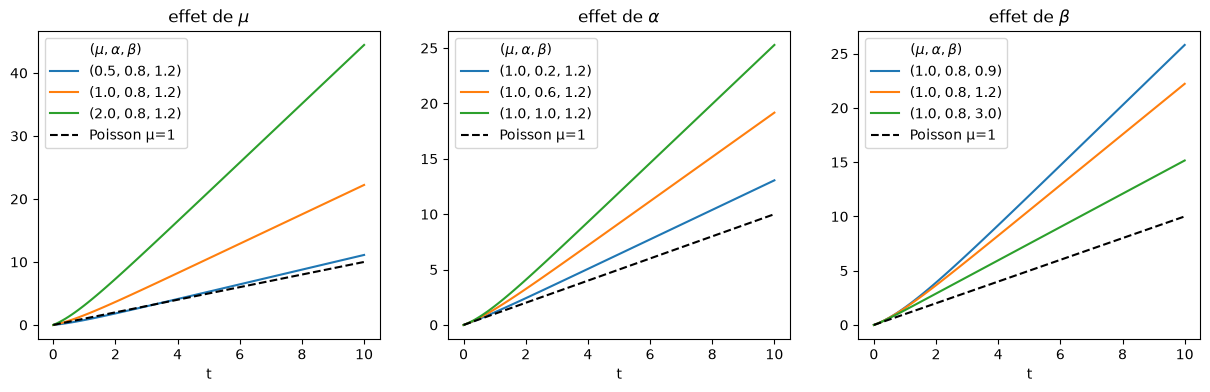

In [6]:
configs = {
    r"$\mu$": [(0.5, 0.8, 1.2), (1.0, 0.8, 1.2), (2.0, 0.8, 1.2)],
    r"$\alpha$": [(1.0, 0.2, 1.2), (1.0, 0.6, 1.2), (1.0, 1.0, 1.2)],
    r"$\beta$": [(1.0, 0.8, 0.9), (1.0, 0.8, 1.2), (1.0, 0.8, 3.0)],
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
print("   mu  alpha  beta |  E[N_T]   Var(N_T)  Var/E  P(multi)")
for j, (nom, liste) in enumerate(configs.items()):
    for (m_, a, b) in liste:
        E = esperance_impact(T, m_, a, b)
        V = variance_impact(T, m_, a, b)
        # P(multi) : proba qu'au moins un point soit induit par plusieurs parents à la fois
        sauts = [simule_impact(T, m_, a, b)[1] for _ in range(2000)]
        p_multi = np.mean([np.any(s > facteur) for s in sauts])
        print(f"{m_:5.1f} {a:6.1f} {b:5.1f} | {E:7.2f} {V:9.1f} {V / E:6.2f} {p_multi:8.2f}")
        ax[j].plot(grille, esperance_impact(grille, m_, a, b), label=f"({m_}, {a}, {b})")
    ax[j].plot(grille, mu * grille, "k--", label="Poisson µ=1")
    ax[j].set(title=f"effet de {nom}", xlabel="t")
    ax[j].legend(title=r"$(\mu,\alpha,\beta)$")
plt.show()

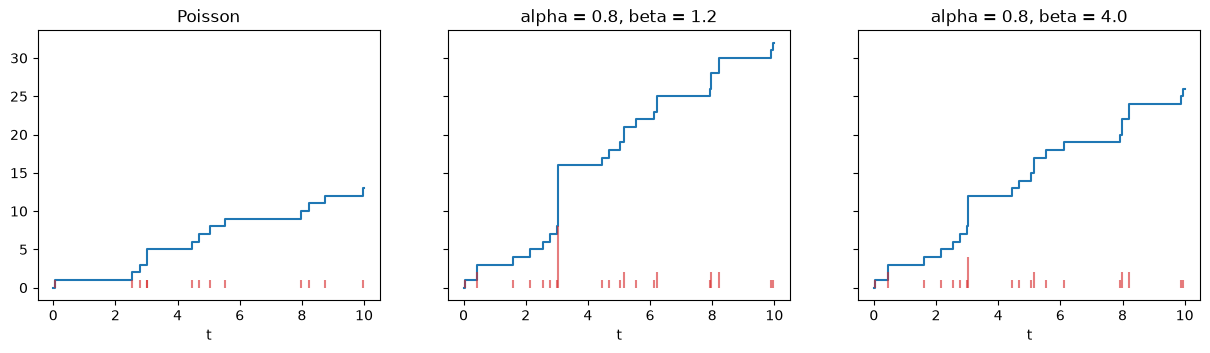

In [7]:
# trois trajectoires avec la même graine : Poisson, impact par défaut, impact qui s'éteint vite
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for j, (a, b) in enumerate([(0.0, 1.2), (0.8, 1.2), (0.8, 4.0)]):
    rng = np.random.default_rng(7)
    tk, sk = simule_poisson(T, mu) if a == 0 else simule_impact(T, mu, a, b)
    ax[j].step(np.r_[0, tk, T], np.r_[0, np.cumsum(sk), sk.sum()], where="post")
    ax[j].vlines(tk, 0, sk, colors="tab:red", alpha=0.6)
    ax[j].set(title=f"alpha = {a}, beta = {b}" if a else "Poisson", xlabel="t")
plt.show()
rng = np.random.default_rng(2025)

Lecture : $\mathbb E[N_t]$ est exactement linéaire en $\mu$ ; augmenter $\mu$ augmente aussi le rapport Var/E car il y a plus de zones qui se chevauchent. Augmenter $\alpha$ (ou diminuer $\beta$) ajoute des sinistres en grappes juste après les sinistres spontanés : l'espérance augmente, mais surtout la variance. Avec $\beta$ grand l'impact s'éteint vite et on retrouve presque un Poisson.

## 5. Montants des sinistres

Cinq lois de même moyenne $m=200$ € pour isoler l'effet de la forme de la loi :

- **discrète « dentaire »** : soin de carie 50 € (55 %), dévitalisation 150 € (25 %), couronne 500 € (15 %), bridge 1200 € (5 %) ;
- **exponentielle** de moyenne 200 ;
- **gamma** $\Gamma(2, 100)$, moins dispersée ;
- **log-normale** $\mathcal{LN}(\ln 200-\tfrac12, 1)$ ;
- **Pareto** $x_m=109.1$, $a=2.2$, queue lourde.

La log-normale et la Pareto n'ont pas de fonction génératrice des moments finie, donc pas de coefficient de Lundberg.

           loi  moyenne  écart-type exact   q99
      dentaire    200.1             276.6   1200
 exponentielle    200.4             200.0    922
         gamma    199.8             141.4    659
   log-normale    201.2             262.2   1263
        Pareto    199.9             301.5    885


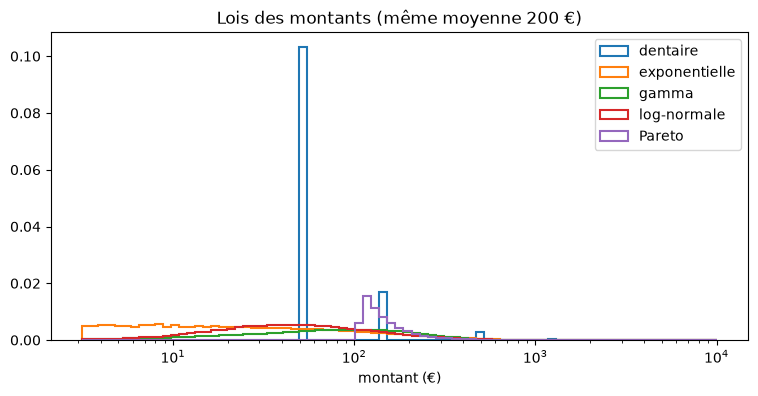

In [8]:
m = 200.0
montants = np.array([50, 150, 500, 1200])
probas = np.array([0.55, 0.25, 0.15, 0.05])
xm, a_par = m * 1.2 / 2.2, 2.2   # Pareto de moyenne 200

# une fonction de tirage par loi (numpy.pareto est une Lomax, d'où le 1 + ...)
lois = {
    "dentaire": lambda n: rng.choice(montants, n, p=probas),
    "exponentielle": lambda n: rng.exponential(m, n),
    "gamma": lambda n: rng.gamma(2, m / 2, n),
    "log-normale": lambda n: rng.lognormal(np.log(m) - 0.5, 1, n),
    "Pareto": lambda n: xm * (1 + rng.pareto(a_par, n)),
}
# variances exactes (plus fiables que l'empirique pour la Pareto)
var_Y = {
    "dentaire": (probas * montants ** 2).sum() - m ** 2,
    "exponentielle": m ** 2,
    "gamma": 2 * (m / 2) ** 2,
    "log-normale": m ** 2 * (np.e - 1),
    "Pareto": xm ** 2 * a_par / ((a_par - 1) ** 2 * (a_par - 2)),
}

fig, ax = plt.subplots(figsize=(9, 4))
print("           loi  moyenne  écart-type exact   q99")
for nom, loi in lois.items():
    y = loi(200000)
    print(f"{nom:>14} {y.mean():8.1f} {np.sqrt(var_Y[nom]):17.1f} {np.quantile(y, 0.99):6.0f}")
    ax.hist(y, bins=np.logspace(0.5, 4, 80), density=True, histtype="step", label=nom, lw=1.5)
ax.set(xscale="log", xlabel="montant (€)", title="Lois des montants (même moyenne 200 €)"); ax.legend()
plt.show()

## 6. Probabilité de ruine

### 6.1 Méthode et validation

La richesse ne baisse qu'aux sauts, il suffit donc de la regarder juste après chaque saut :
$$\psi(u,T)=\mathbb P\Big(\min_{j}\big(c\,t_j-L_j\big)<-u\Big)$$
où $L_j$ est le montant cumulé au $j$-ème saut. $u$ n'intervient qu'en translation : une seule simulation donne $\psi(u,T)$ pour tous les $u$.

Prime par le principe de l'espérance sur $[0,T]$ : $cT=(1+\eta)\,\mathbb E[N_T]\,m$ avec $\eta=20\%$.

In [9]:
eta = 0.2
us = np.linspace(0, 3000, 61)
u0 = 1000
i0 = np.searchsorted(us, u0)

def marge_min(temps, sauts, c, loi):
    # plus petite valeur de c*t - pertes, regardée juste après chaque saut
    if len(temps) == 0:
        return 0.0
    y = loi(sauts.sum())                         # un montant par sinistre
    pertes = np.cumsum(y)[np.cumsum(sauts) - 1]  # pertes cumulées après chaque saut
    return min(0.0, (c * temps - pertes).min())

def ic(p, K):
    # demi-largeur de l'intervalle de confiance à 95 % d'une proba estimée sur K trajectoires
    return 1.96 * np.sqrt(p * (1 - p) / K)

def psi(trajs, c, loi):
    # ruine si u + marge_min < 0, pour tous les u d'un coup
    mins = np.array([marge_min(t, s, c, loi) for t, s in trajs])
    return np.array([(u + mins < 0).mean() for u in us])

Pour contrôler le calcul de la ruine, on simule le cas Poisson à montants exponentiels jusqu’à $T=200$ et on compare la courbe à la formule du cours en horizon infini, $\psi(u)=\frac{1}{1+\eta}e^{-\eta u/((1+\eta)m)}$. À horizon fini, la probabilité théorique est au plus égale à cette limite.

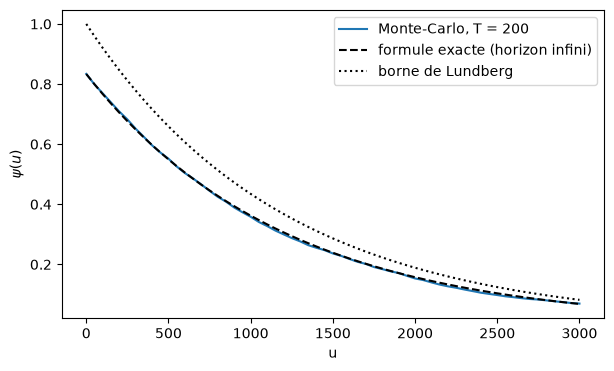

In [10]:
c_poisson = (1 + eta) * mu * m
val = [simule_poisson(200.0, mu) for _ in range(5000)]
plt.figure(figsize=(7, 4))
plt.plot(us, psi(val, c_poisson, lois["exponentielle"]), label="Monte-Carlo, T = 200")
plt.plot(us, np.exp(-eta * us / ((1 + eta) * m)) / (1 + eta), "k--", label="formule exacte (horizon infini)")
plt.plot(us, np.exp(-(1 / m - mu / c_poisson) * us), "k:", label="borne de Lundberg")
plt.xlabel("u")
plt.ylabel(r"$\psi(u)$")
plt.legend()
plt.show()

### 6.2 Comparaison des modèles

prime c (€/an) : {'Poisson': 240.0, 'impact': 533.3, 'Hawkes': 602.2}


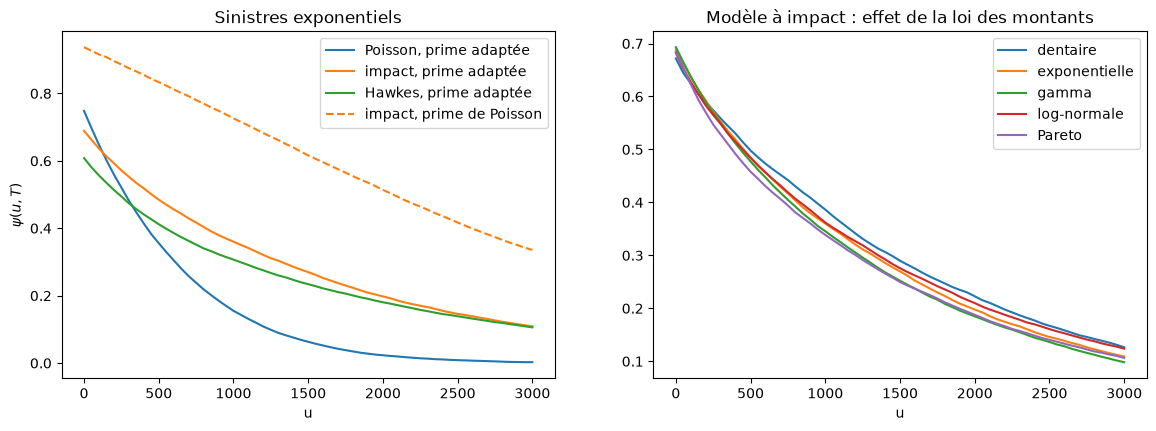

psi(u=1000, T=10), intervalle de confiance à 95 % : ± 0.007 au plus
           loi |  Poisson   impact   Hawkes | impact, prime Poisson
      dentaire |    0.227    0.386    0.335 |    0.711
 exponentielle |    0.155    0.360    0.307 |    0.726
         gamma |    0.112    0.346    0.282 |    0.729
   log-normale |    0.173    0.362    0.311 |    0.703
        Pareto |    0.115    0.339    0.280 |    0.714


In [11]:
K = 20000
traj = {
    "Poisson": [simule_poisson(T, mu) for _ in range(K)],
    "impact": [simule_impact(T, mu, alpha, beta) for _ in range(K)],
    "Hawkes": [simule_hawkes(T, mu, alpha, beta) for _ in range(K)],
}
EN = {"Poisson": mu * T, "impact": esperance_impact(T, mu, alpha, beta), "Hawkes": esperance_hawkes(T, mu, alpha, beta)}
c = {k: (1 + eta) * EN[k] * m / T for k in EN}
print("prime c (€/an) :", {k: round(float(v), 1) for k, v in c.items()})

# psi pour chaque modèle et chaque loi, avec la prime adaptée au modèle
res = {(k, nom): psi(traj[k], c[k], loi) for k in traj for nom, loi in lois.items()}
# l'assureur garde la prime de Poisson alors que les sinistres s'auto-excitent
res_pp = {nom: psi(traj["impact"], c["Poisson"], loi) for nom, loi in lois.items()}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k in traj:
    ax[0].plot(us, res[(k, "exponentielle")], label=f"{k}, prime adaptée")
ax[0].plot(us, res_pp["exponentielle"], "--", c="tab:orange", label="impact, prime de Poisson")
ax[0].set(xlabel="u", ylabel=r"$\psi(u,T)$", title="Sinistres exponentiels")
ax[0].legend()
for nom in lois:
    ax[1].plot(us, res[("impact", nom)], label=nom)
ax[1].set(xlabel="u", title="Modèle à impact : effet de la loi des montants")
ax[1].legend()
plt.show()

print(f"psi(u={u0}, T={T:.0f}), intervalle de confiance à 95 % : ± {ic(0.5, K):.3f} au plus")
print("           loi |  Poisson   impact   Hawkes | impact, prime Poisson")
for nom in lois:
    print(
        f"{nom:>14} | {res[('Poisson', nom)][i0]:8.3f} {res[('impact', nom)][i0]:8.3f} "
        f"{res[('Hawkes', nom)][i0]:8.3f} | {res_pp[nom][i0]:8.3f}"
    )

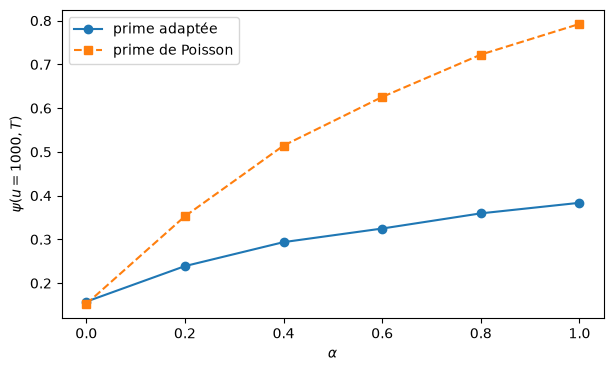

In [12]:
# effet de alpha sur la ruine (alpha = 0 : Poisson)
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
p_adaptee, p_poisson = [], []
for a in alphas:
    tr = [simule_impact(T, mu, a, beta) if a > 0 else simule_poisson(T, mu) for _ in range(10000)]
    ca = (1 + eta) * esperance_impact(T, mu, a, beta) * m / T
    p_adaptee.append(psi(tr, ca, lois["exponentielle"])[i0])
    p_poisson.append(psi(tr, c["Poisson"], lois["exponentielle"])[i0])
plt.figure(figsize=(7, 4))
plt.plot(alphas, p_adaptee, "o-", label="prime adaptée")
plt.plot(alphas, p_poisson, "s--", label="prime de Poisson")
plt.xlabel(r"$\alpha$")
plt.ylabel(fr"$\psi(u={u0},T)$")
plt.legend()
plt.show()

Avec 1 000 € de réserve et une prime de 240 €/an, la ruine à dix ans passe de 15,5 % sous Poisson à 72,6 % dans le modèle à impact, pour des montants exponentiels. Le nombre moyen de sinistres passe aussi de 10 à 22,22. En portant la prime du modèle à impact à 533,3 €/an, on ramène la ruine estimée à 36,0 %. La section suivante compare les deux modèles à prime commune.

Avec leurs primes respectives, le Hawkes donne 30,7 % et le modèle à impact 36,0 %. Leurs fréquences et leurs phases de démarrage diffèrent. Cette expérience ne permet pas d’attribuer l’écart à l’un de ces facteurs en particulier.

### 6.3 Comparaison à nombre moyen de sinistres égal (*Complément*)

Non demandé dans l'énoncé : on l'a fait pour vérifier que l'écart de ruine ne vient pas seulement du nombre moyen de sinistres. On compare à un Poisson d'intensité $\lambda_{eq}=\mathbb E[N_T]/T$ : même nombre moyen de sinistres sur $[0,T]$, donc même prime. Seule la structure des arrivées change : grappes, phase de démarrage (le modèle à impact a moins de sinistres au début et plus à la fin) et arrivées simultanées. Les séparer demanderait par exemple un Poisson non homogène de même courbe moyenne, ce qu'on n'a pas fait.

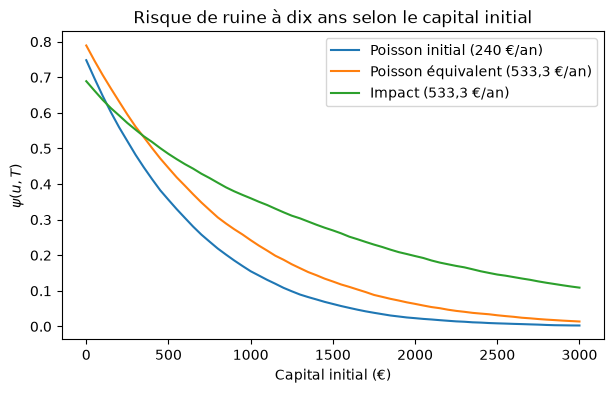

lambda_eq = 2.222, prime commune c = 533.3
psi(u=1000, T=10) à prime égale
           loi | Poisson équivalent           impact           écart
      dentaire | 0.328 ± 0.007    0.386 ± 0.007     +18%
 exponentielle | 0.242 ± 0.006    0.360 ± 0.007     +49%
         gamma | 0.182 ± 0.005    0.346 ± 0.007     +90%
   log-normale | 0.266 ± 0.006    0.362 ± 0.007     +36%
        Pareto | 0.184 ± 0.005    0.339 ± 0.007     +84%


In [13]:
lam_eq = EN["impact"] / T
traj_eq = [simule_poisson(T, lam_eq) for _ in range(K)]
res_eq = {nom: psi(traj_eq, c["impact"], loi) for nom, loi in lois.items()}

plt.figure(figsize=(7, 4))
plt.plot(us, res[("Poisson", "exponentielle")], label="Poisson initial (240 €/an)")
plt.plot(us, res_eq["exponentielle"], label="Poisson équivalent (533,3 €/an)")
plt.plot(us, res[("impact", "exponentielle")], label="Impact (533,3 €/an)")
plt.xlabel("Capital initial (€)")
plt.ylabel(r"$\psi(u,T)$")
plt.title("Risque de ruine à dix ans selon le capital initial")
plt.legend()
plt.show()

print(f"lambda_eq = {lam_eq:.3f}, prime commune c = {c['impact']:.1f}")
print(f"psi(u={u0}, T={T:.0f}) à prime égale")
print("           loi | Poisson équivalent           impact           écart")
for nom in lois:
    p_eq, p_im = res_eq[nom][i0], res[("impact", nom)][i0]
    print(f"{nom:>14} | {p_eq:.3f} ± {ic(p_eq, K):.3f}    {p_im:.3f} ± {ic(p_im, K):.3f}  {p_im / p_eq - 1:+7.0%}")

Avec 1 000 € de capital, des montants exponentiels et une prime commune de 533,3 €/an, la ruine à dix ans passe de 24,2 % à 36,0 %, soit 11,8 points de plus (+49 % en relatif). Les deux modèles ont pourtant la même moyenne de 22,22 sinistres à dix ans. La comparaison mesure ensemble les effets du démarrage, des grappes et des sinistres simultanés. Parmi les cinq lois testées, la hausse relative va de 18 % pour le barème dentaire à 90 % pour la gamma.

### 6.4 Une prime qui tient compte de la variance (*Complément*)

Non demandé dans l'énoncé : on l'a ajouté pour voir comment corriger le problème mis en évidence au-dessus.

Principe de la variance : $\pi_T=\mathbb E[S_T]+\delta\operatorname{Var}(S_T)$ avec
$$\operatorname{Var}(S_T)=\mathbb E[N_T]\operatorname{Var}(Y)+\operatorname{Var}(N_T)\,m^2$$
(valable ici car les $Y_i$ sont i.i.d. et indépendants de $N$, même avec des sauts de taille $>1$). On prend $\delta=\eta/(2m)$, ce qui redonne 20 % de chargement pour Poisson + exponentielle, et on garde ce $\delta$ partout. On compare les deux modèles avec ce même principe.

In [14]:
delta = eta / (2 * m)
VarN = {"Poisson": mu * T, "impact": variance_impact(T, mu, alpha, beta)}

def prime_variance(k, nom):
    ES = EN[k] * m
    VS = EN[k] * var_Y[nom] + VarN[k] * m ** 2
    return (ES + delta * VS) / T

print("           loi |  c Poisson  c impact | psi Poisson  psi impact (var.)  psi impact (esp.)")
for nom, loi in lois.items():
    cp, ci = prime_variance("Poisson", nom), prime_variance("impact", nom)
    pp = psi(traj["Poisson"], cp, loi)[i0]
    pi = psi(traj["impact"], ci, loi)[i0]
    print(f"{nom:>14} | {cp:10.1f} {ci:9.1f} | {pp:11.3f} {pi:18.3f} {res[('impact', nom)][i0]:18.3f}")
print(f"intervalle de confiance à 95 % : ± {ic(0.4, K):.3f} au plus")

           loi |  c Poisson  c impact | psi Poisson  psi impact (var.)  psi impact (esp.)


      dentaire |      258.2     752.4 |       0.200              0.233              0.386


 exponentielle |      240.0     711.9 |       0.156              0.225              0.360


         gamma |      230.0     689.6 |       0.127              0.221              0.346


   log-normale |      254.4     743.8 |       0.157              0.222              0.362


        Pareto |      265.5     768.4 |       0.085              0.176              0.339
intervalle de confiance à 95 % : ± 0.007 au plus


Pour les montants exponentiels, le chargement fondé sur la variance porte la prime annuelle de 533,3 € à 711,9 €. La ruine estimée sur dix ans passe alors de 36,0 % à 22,5 %. Tout tarif qui aboutit à la même prime donne ici la même probabilité théorique de ruine. Le choix entre ces tarifs dépend du niveau de risque que l’assureur accepte.

### 6.5 Que change le facteur 2 du sujet ? (*Complément*)

Non demandé dans l'énoncé : on l'a fait pour vérifier la robustesse de nos conclusions. Le facteur 2 double le nombre de sinistres induits. On refait les calculs principaux avec le poids 1 de l'article pour voir ce qui en dépend.

In [15]:
print(f"10 000 trajectoires : intervalle de confiance à 95 % ± {ic(0.5, 10000):.3f} au plus")
print("facteur |  E[N_T]  Var(N_T)  Var/E | prime Poisson / adaptée | impact vs Poisson équivalent")
for f in [2, 1]:
    E, V = esperance_impact(T, mu, alpha, beta, f), variance_impact(T, mu, alpha, beta, f)
    tr = [simule_impact(T, mu, alpha, beta, f) for _ in range(10000)]
    teq = [simule_poisson(T, E / T) for _ in range(10000)]
    cf = (1 + eta) * E * m / T
    p_pp = psi(tr, c["Poisson"], lois["exponentielle"])[i0]
    p_im = psi(tr, cf, lois["exponentielle"])[i0]
    p_eq = psi(teq, cf, lois["exponentielle"])[i0]
    print(
        f"{f:7d} | {E:7.2f} {V:9.1f} {V / E:6.2f} | {p_pp:.3f} "
        f"/ {p_im:.3f} (x{p_pp / res[('Poisson', 'exponentielle')][i0]:.1f} "
        f"vs Poisson) | {p_im:.3f} vs {p_eq:.3f} ({p_im / p_eq - 1:+.0%})"
    )

10 000 trajectoires : intervalle de confiance à 95 % ± 0.010 au plus
facteur |  E[N_T]  Var(N_T)  Var/E | prime Poisson / adaptée | impact vs Poisson équivalent


      2 |   22.22     111.5   5.02 | 0.726 / 0.363 (x4.7 vs Poisson) | 0.363 vs 0.245 (+48%)


      1 |   16.11      41.5   2.57 | 0.515 / 0.274 (x3.3 vs Poisson) | 0.274 vs 0.208 (+31%)


En gardant les zones d’impact du sujet, passer du poids 2 au poids 1 ramène le nombre moyen de sinistres à dix ans de 22,22 à 16,11. Avec des montants exponentiels, l’écart relatif de ruine avec le Poisson de même moyenne passe de 48 % à 31 % dans cette simulation. Le poids 2 reste celui du scénario principal.

### 6.6 Horizon long (*Complément*)

Non demandé dans l'énoncé : on l'a fait pour comparer avec les résultats du cours, qui sont en horizon infini. Les résultats du cours portent sur $\psi(u)=\mathbb P(\tau<\infty)$. On regarde $\psi(u,T)$ pour des horizons croissants. Sur un horizon long la prime doit couvrir le régime permanent : $c=(1+\eta)\,\mu(1+2\alpha/\beta)\,m$, et on compare à un Poisson de même taux limite. Pour Poisson, la formule exacte ne dépend pas de l'intensité, elle sert de repère.

T =  10 : psi(u=1000) Poisson = 0.249 ± 0.015   impact = 0.329 ± 0.017


T =  50 : psi(u=1000) Poisson = 0.351 ± 0.017   impact = 0.519 ± 0.018


T = 100 : psi(u=1000) Poisson = 0.359 ± 0.017   impact = 0.533 ± 0.018
formule exacte Poisson : 0.362   borne de Lundberg 'Poisson' : 0.435


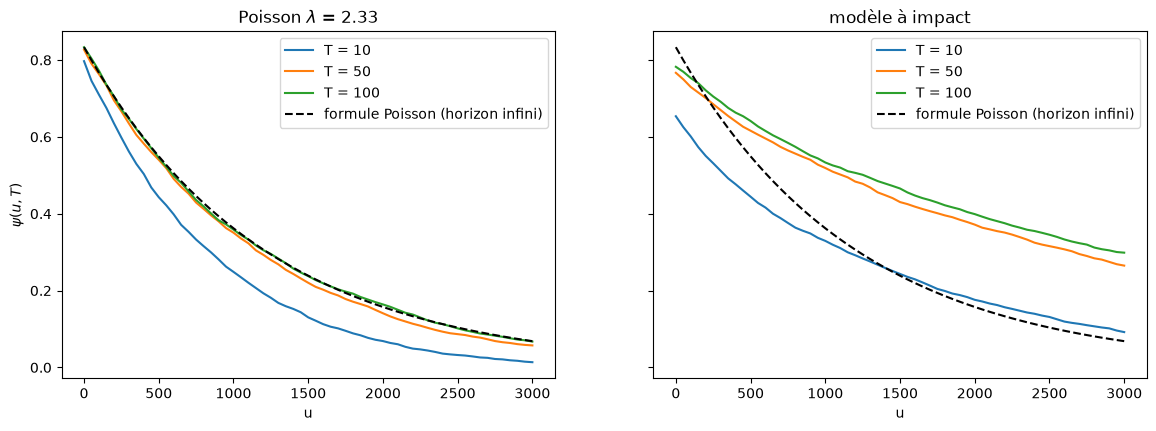

In [16]:
lam_inf = mu * (1 + facteur * alpha / beta)
c_inf = (1 + eta) * lam_inf * m
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for Tl in [10, 50, 100]:
    tp = [simule_poisson(Tl, lam_inf) for _ in range(3000)]
    ti = [simule_impact(Tl, mu, alpha, beta) for _ in range(3000)]
    pp, pi = psi(tp, c_inf, lois["exponentielle"]), psi(ti, c_inf, lois["exponentielle"])
    ax[0].plot(us, pp, label=f"T = {Tl}")
    ax[1].plot(us, pi, label=f"T = {Tl}")
    print(
        f"T = {Tl:3d} : psi(u={u0}) Poisson = {pp[i0]:.3f} "
        f"± {ic(pp[i0], 3000):.3f}   impact = {pi[i0]:.3f} "
        f"± {ic(pi[i0], 3000):.3f}"
    )
exact = np.exp(-eta * us / ((1 + eta) * m)) / (1 + eta)
print(
    f"formule exacte Poisson : {exact[i0]:.3f}   borne "
    f"de Lundberg 'Poisson' : {np.exp(-(1 / m - lam_inf / c_inf) * u0):.3f}"
)
for a in ax:
    a.plot(us, exact, "k--", label="formule Poisson (horizon infini)")
    a.set(xlabel="u")
    a.legend()
ax[0].set(title=fr"Poisson $\lambda$ = {lam_inf:.2f}", ylabel=r"$\psi(u,T)$")
ax[1].set(title="modèle à impact")
plt.show()

À 100 ans, la ruine estimée sous Poisson vaut 35,9 %, près de la valeur exacte de 36,2 % en horizon infini. Pour le modèle à impact, les estimations passent de 51,9 % à 50 ans à 53,3 % à 100 ans. Les deux échantillons sont indépendants. La différence de 1,4 point a une marge d’environ 2,5 points à 95 % : ces simulations ne permettent pas de chiffrer précisément la hausse sur cet intervalle.

À 100 ans, l’intervalle estimé pour le modèle à impact (53,3 % ± 1,8 point) se situe déjà au-dessus de 43,5 %, valeur obtenue avec le coefficient de Lundberg du Poisson. Utiliser ce coefficient pour le modèle à impact sous-estimerait donc le risque dans cet exemple.

### 6.7 Remarque sur les sauts de taille $k>1$

Un saut de taille $k$ est lu comme $k$ sinistres de montants indépendants survenus au même instant. C'est cohérent avec la définition de $N^{(2)}$, qui compte des couples (parent, enfant), et Wald reste vrai : $\mathbb E[S_T]=\mathbb E[N_T]\,m$. Une autre lecture serait un seul sinistre de montant multiplié par $k$ : même espérance, mais variance encore plus grande.

## 7. Propriétés du cours : que deviennent-elles ?

| Propriété | Poisson | Modèle à impact |
|---|---|---|
| accroissements indépendants | oui | non (un sinistre influence le futur) |
| accroissements stationnaires | oui | non, $\mathbb E[N_t]$ n'est pas linéaire au début |
| loi de $N_t$ | $\mathcal P(\mu t)$ | pas de forme simple ; $\operatorname{Var}>\mathbb E$ |
| sauts de taille 1 | oui | non (sinistres simultanés) |
| $\mathbb E[N_t]$ | $\mu t$ | $\mu t+2\frac{\mu\alpha}{\beta}\big(t-\frac{1-e^{-\beta t}}{\beta}\big)$ |
| Wald $\mathbb E[S_t]=\mathbb E[N_t]m$ | oui | oui ($Y$ indépendants de $N$) |
| $\operatorname{Var}(S_t)$ | $\mu t\,\mathbb E[Y^2]$ | $\mathbb E[N_t]\operatorname{Var}(Y)+\operatorname{Var}(N_t)\,m^2$ |
| profit net | $c>\mu m$ | $c>\mu(1+2\alpha/\beta)\,m$ |
| formule de ruine, Lundberg | oui | la preuve du cours (accroissements indépendants) ne s'applique plus, pas de formule fermée : Monte-Carlo |

## 8. Synthèse des résultats

Chaque sinistre spontané, de fréquence $\mu$, ouvre une zone où d’autres sinistres peuvent survenir. $\alpha$ règle la hauteur initiale de cette zone et $1/\beta$ sa durée caractéristique. Plusieurs zones peuvent se recouvrir. Avec les paramètres retenus, on attend 22,22 sinistres en dix ans et la variance du comptage vaut 111,5.

Pour une réserve de 1 000 € et des montants exponentiels, deux comparaisons éclairent la décision tarifaire.

- **Garder le tarif initial de 240 €/an.** La ruine à dix ans passe de 15,5 % sous Poisson à 72,6 % sous impact. Le tarif initial couvre un portefeuille qui compte en moyenne dix sinistres sur cette période.
- **Comparer à volume et à prime identiques.** Avec 22,22 sinistres attendus et 533,3 €/an dans les deux modèles, la ruine atteint 24,2 % sous Poisson et 36,0 % sous impact. Connaître le volume moyen ne suffit donc pas pour évaluer le risque.

Dans le modèle à impact, un tarif de 711,9 €/an ramène la ruine estimée à 22,5 %. Ces chiffres correspondent aux paramètres du BE et à un portefeuille simulé. Pour choisir un tarif, il reste à fixer le risque acceptable pour l’assureur.